# India Census 2011 — Insight Lab

**AICTE | IBM SkillsBuild Data Analytics with AI Internship 2026**

This is the ** Jupyter Notebook version** of the final project.

Everything needed for the project is contained in this one `.ipynb`:

- Python data analytics
- Machine-learning model
- Flask backend
- REST API
- Frontend HTML
- Frontend CSS
- Frontend JavaScript
- Interactive charts
- District explorer
- Interactive prediction panel
- Project documentation

### Dataset source

**Kaggle:** https://www.kaggle.com/danofer/india-census

**Kaggle dataset file:** https://www.kaggle.com/datasets/danofer/india-census?select=india-districts-census-2011.csv

The notebook downloads the public CSV mirror of the same district-level Census 2011 file at runtime so the project does not need Kaggle API credentials.

> **Important:** The dataset is historical 2011 Census data. The dashboard is an educational analytics project and must not be interpreted as a current 2026 population/literacy system or as a causal decision tool.


## 1. Install / Import Dependencies

The notebook uses only common Python libraries:

- pandas
- numpy
- scikit-learn
- Flask
- requests
- matplotlib

The web dashboard itself uses Chart.js from a public CDN for browser-side visualization.


In [1]:
# Run this cell once in a fresh environment if dependencies are missing.
# !pip install -q pandas numpy scikit-learn flask requests matplotlib

from pathlib import Path
import os
import threading
import time
import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from flask import Flask, jsonify, render_template_string, request


In [2]:
# ---------------------------------------------------------
# 2. Download and load the Kaggle-sourced Census 2011 file
# ---------------------------------------------------------

DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)

DATA_FILE = DATA_DIR / "india-districts-census-2011.csv"

KAGGLE_URL = "https://www.kaggle.com/danofer/india-census"
KAGGLE_FILE_URL = "https://www.kaggle.com/datasets/danofer/india-census?select=india-districts-census-2011.csv"
RAW_DATA_URL = "https://raw.githubusercontent.com/nishusharma1608/India-Census-2011-Analysis/master/india-districts-census-2011.csv"

if not DATA_FILE.exists():
    print("Downloading dataset...")
    response = requests.get(RAW_DATA_URL, timeout=60)
    response.raise_for_status()
    DATA_FILE.write_bytes(response.content)
    print("Dataset downloaded.")

df = pd.read_csv(DATA_FILE)

print("Rows:", len(df))
print("Columns:", len(df.columns))
print("Districts:", df["District name"].nunique())
print("States / UT labels:", df["State name"].nunique())

display(df.head())


Rows: 640
Columns: 118
Districts: 634
States / UT labels: 35


,District code,State name,District name,Population,Male,Female,Literate,Male_Literate,Female_Literate,SC,...,Power_Parity_Rs_90000_150000,Power_Parity_Rs_45000_150000,Power_Parity_Rs_150000_240000,Power_Parity_Rs_240000_330000,Power_Parity_Rs_150000_330000,Power_Parity_Rs_330000_425000,Power_Parity_Rs_425000_545000,Power_Parity_Rs_330000_545000,Power_Parity_Above_Rs_545000,Total_Power_Parity
0,1,JAMMU AND KASHMIR,Kupwara,870354,474190,396164,439654,282823,156831,1048,...,94,588,71,101,172,74,10,84,15,1119
1,2,JAMMU AND KASHMIR,Badgam,753745,398041,355704,335649,207741,127908,368,...,126,562,72,89,161,96,28,124,18,1066
2,3,JAMMU AND KASHMIR,Leh(Ladakh),133487,78971,54516,93770,62834,30936,488,...,46,122,15,22,37,20,14,34,17,242
3,4,JAMMU AND KASHMIR,Kargil,140802,77785,63017,86236,56301,29935,18,...,27,114,12,18,30,19,3,22,7,214
4,5,JAMMU AND KASHMIR,Punch,476835,251899,224936,261724,163333,98391,556,...,78,346,35,50,85,59,8,67,12,629


## 3. Data Understanding and Cleaning

The project checks duplicates, converts key measures to numeric values, and creates rate-based variables.

Rate-based variables are important because raw population or household counts can be dominated by large districts.


In [3]:
# Data quality checks
print("Duplicate rows:", df.duplicated().sum())

key_columns = [
    "State name", "District name", "Population", "Male", "Female",
    "Literate", "Workers", "Households"
]

print("\nMissing values in important columns:")
display(df[key_columns].isna().sum())

numeric_cols = [
    "Population", "Male", "Female", "Literate", "Workers", "Households",
    "Housholds_with_Electric_Lighting", "Households_with_Internet",
    "Households_with_Computer", "LPG_or_PNG_Households",
    "Households_with_Television", "Households_with_Telephone_Mobile_Phone",
    "Urban_Households", "Households_with_Car_Jeep_Van",
    "Households_with_Scooter_Motorcycle_Moped"
]

for col in numeric_cols:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

df = df.drop_duplicates().copy()

print("\nClean shape:", df.shape)


Duplicate rows: 0

Missing values in important columns:


State name       0
District name    0
Population       0
Male             0
Female           0
Literate         0
Workers          0
Households       0
dtype: int64


Clean shape: (640, 118)


In [4]:
# Derived metrics
def pct(num, den):
    denominator = df[den].replace(0, np.nan)
    return df[num] / denominator * 100

df["literacy_rate"] = pct("Literate", "Population")
df["female_share"] = pct("Female", "Population")
df["workers_share"] = pct("Workers", "Population")
df["urban_share"] = pct("Urban_Households", "Households")
df["electricity_pct"] = pct("Housholds_with_Electric_Lighting", "Households")
df["internet_pct"] = pct("Households_with_Internet", "Households")
df["computer_pct"] = pct("Households_with_Computer", "Households")
df["lpg_pct"] = pct("LPG_or_PNG_Households", "Households")
df["television_pct"] = pct("Households_with_Television", "Households")
df["telephone_pct"] = pct("Households_with_Telephone_Mobile_Phone", "Households")
df["car_pct"] = pct("Households_with_Car_Jeep_Van", "Households")
df["motorcycle_pct"] = pct("Households_with_Scooter_Motorcycle_Moped", "Households")
df["sex_ratio"] = df["Female"] / df["Male"].replace(0, np.nan) * 1000

display(df[[
    "District name", "State name", "Population",
    "literacy_rate", "sex_ratio", "electricity_pct", "internet_pct"
]].head(10))


,District name,State name,Population,literacy_rate,sex_ratio,electricity_pct,internet_pct
0,Kupwara,JAMMU AND KASHMIR,870354,50.514388,835.454143,45.727827,0.419456
1,Badgam,JAMMU AND KASHMIR,753745,44.530843,893.636585,48.014523,1.064209
2,Leh(Ladakh),JAMMU AND KASHMIR,133487,70.246541,690.329361,31.713057,1.055263
3,Kargil,JAMMU AND KASHMIR,140802,61.246289,810.143344,32.868062,0.488119
4,Punch,JAMMU AND KASHMIR,476835,54.887749,892.961068,42.670683,0.234723
5,Rajouri,JAMMU AND KASHMIR,642415,56.678160,860.179933,44.954068,0.315107
6,Kathua,JAMMU AND KASHMIR,616435,63.137882,890.272884,50.930197,0.671641
7,Baramula,JAMMU AND KASHMIR,1008039,54.080150,885.125848,53.253685,1.425185
8,Bandipore,JAMMU AND KASHMIR,392232,47.415560,888.636364,46.360985,1.004323
9,Srinagar,JAMMU AND KASHMIR,1236829,60.524454,899.529122,63.073380,6.258794


## 4.  Descriptive Analysis

### Five observations

1. Population is concentrated across states rather than being evenly distributed.
2. Aggregate literacy rates differ across states.
3. Sex-ratio values vary across state aggregates.
4. Household electricity coverage varies across state aggregates.
5. Internet coverage creates another dimension for comparing digital access.

The next cells create the five visualizations used to support those observations.


In [5]:
# State-level aggregation
state = df.groupby("State name").agg({
    "Population": "sum",
    "Male": "sum",
    "Female": "sum",
    "Literate": "sum",
    "Workers": "sum",
    "Households": "sum",
    "Housholds_with_Electric_Lighting": "sum",
    "Households_with_Internet": "sum",
    "Households_with_Computer": "sum",
    "Urban_Households": "sum"
}).reset_index()

state["literacy_rate"] = state["Literate"] / state["Population"] * 100
state["sex_ratio"] = state["Female"] / state["Male"] * 1000
state["electricity_pct"] = (
    state["Housholds_with_Electric_Lighting"] / state["Households"] * 100
)
state["internet_pct"] = state["Households_with_Internet"] / state["Households"] * 100
state["urban_share"] = state["Urban_Households"] / state["Households"] * 100

display(state.head())


,State name,Population,Male,Female,Literate,Workers,Households,Housholds_with_Electric_Lighting,Households_with_Internet,Households_with_Computer,Urban_Households,literacy_rate,sex_ratio,electricity_pct,internet_pct,urban_share
0,ANDAMAN AND NICOBAR ISLANDS,380581,202871,177710,294281,152535,141675,80421,3234,8194,51725,77.324144,875.975374,56.764426,2.282689,36.509617
1,ANDHRA PRADESH,84580777,42442146,42138631,50556760,39422906,25594996,19377222,549284,1763555,8420919,59.773345,992.848736,75.707072,2.146060,32.900646
2,ARUNACHAL PRADESH,1383727,713912,669815,766005,587657,375960,171821,5128,21247,105414,55.358102,938.231883,45.701936,1.363975,28.038621
3,ASSAM,31205576,15939443,15266133,19177977,11969690,9074503,2358900,100173,593484,1485505,61.456892,957.758248,25.994812,1.103895,16.370098
4,BIHAR,104099452,54278157,49821295,52504553,34724987,23414674,3098435,165521,1334565,2701332,50.436916,917.888480,13.232877,0.706911,11.536919


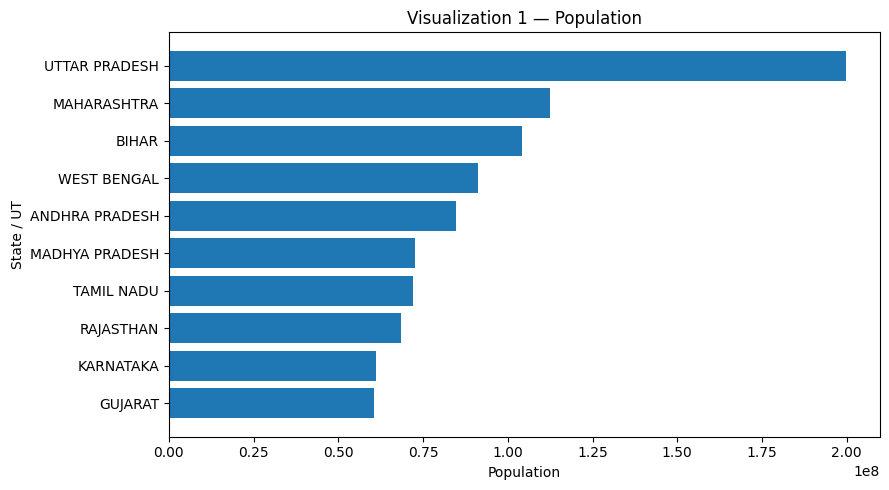

In [6]:
# Visualization 1 — Population
plot_df = state.nlargest(10, "Population").sort_values("Population")

plt.figure(figsize=(9, 5))
plt.barh(plot_df["State name"], plot_df["Population"])
plt.title("Visualization 1 — Population")
plt.xlabel("Population")
plt.ylabel("State / UT")
plt.tight_layout()
plt.show()


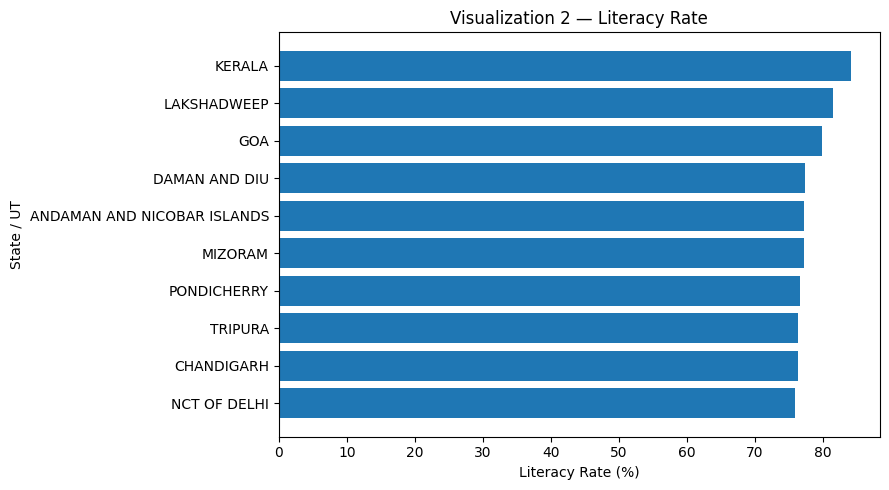

In [7]:
# Visualization 2 — Literacy Rate
plot_df = state.nlargest(10, "literacy_rate").sort_values("literacy_rate")

plt.figure(figsize=(9, 5))
plt.barh(plot_df["State name"], plot_df["literacy_rate"])
plt.title("Visualization 2 — Literacy Rate")
plt.xlabel("Literacy Rate (%)")
plt.ylabel("State / UT")
plt.tight_layout()
plt.show()


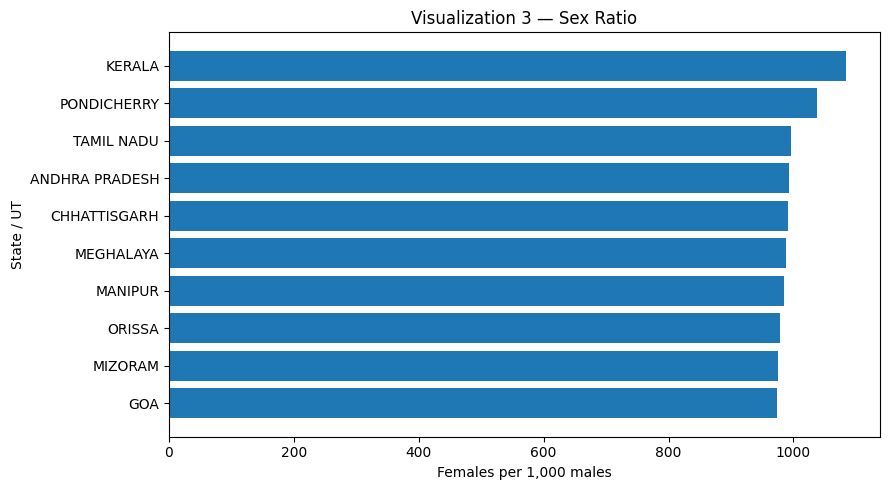

In [8]:
# Visualization 3 — Sex Ratio
plot_df = state.nlargest(10, "sex_ratio").sort_values("sex_ratio")

plt.figure(figsize=(9, 5))
plt.barh(plot_df["State name"], plot_df["sex_ratio"])
plt.title("Visualization 3 — Sex Ratio")
plt.xlabel("Females per 1,000 males")
plt.ylabel("State / UT")
plt.tight_layout()
plt.show()


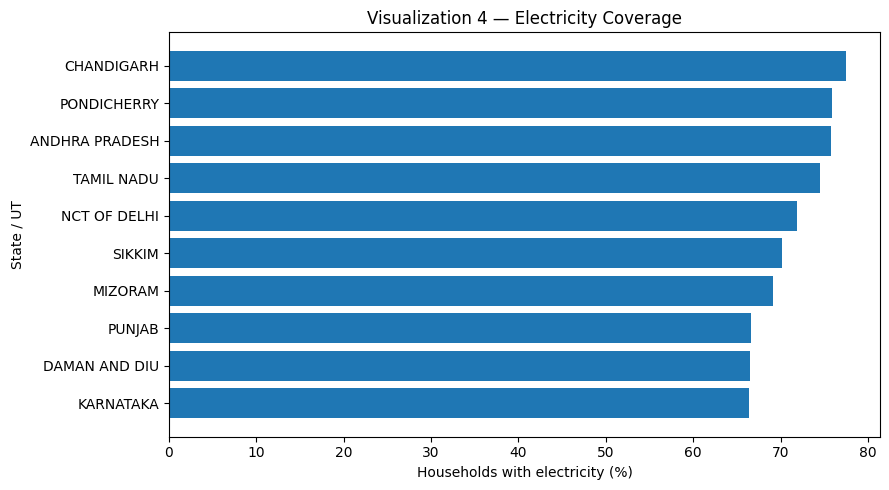

In [9]:
# Visualization 4 — Electricity Coverage
plot_df = state.nlargest(10, "electricity_pct").sort_values("electricity_pct")

plt.figure(figsize=(9, 5))
plt.barh(plot_df["State name"], plot_df["electricity_pct"])
plt.title("Visualization 4 — Electricity Coverage")
plt.xlabel("Households with electricity (%)")
plt.ylabel("State / UT")
plt.tight_layout()
plt.show()


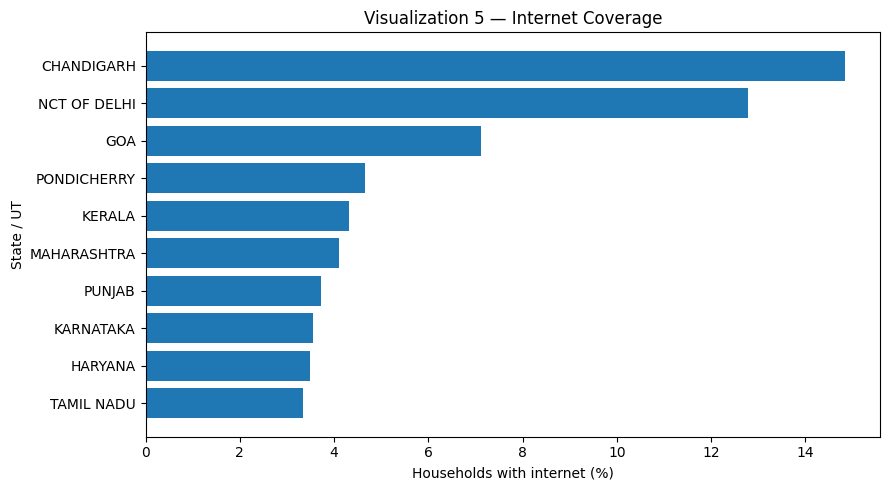

In [10]:
# Visualization 5 — Internet Coverage
plot_df = state.nlargest(10, "internet_pct").sort_values("internet_pct")

plt.figure(figsize=(9, 5))
plt.barh(plot_df["State name"], plot_df["internet_pct"])
plt.title("Visualization 5 — Internet Coverage")
plt.xlabel("Households with internet (%)")
plt.ylabel("State / UT")
plt.tight_layout()
plt.show()


## 5. Five Insights

### Insight 1 — Population concentration matters
Raw population counts can dominate comparisons, so rates and percentages are useful when comparing districts or states of different sizes.

### Insight 2 — Literacy varies geographically
State-level literacy rates differ, indicating meaningful geographic variation in recorded literacy outcomes.

### Insight 3 — Demographic structure varies
Sex-ratio differences across state aggregates show that demographic composition is not uniform.

### Insight 4 — Basic infrastructure is uneven
Household electricity coverage can be compared with other socioeconomic and demographic indicators to identify patterns worth investigating.

### Insight 5 — Digital access adds another development lens
Internet and computer access provide additional dimensions for examining differences in household infrastructure.


## 6. Three Hypotheses

These are possible explanations for observed patterns. They are **not** confirmed causal claims.

1. Districts with higher household electricity and digital-access coverage may also show higher literacy rates.

2. Districts with a larger urban-household share may display different literacy patterns from districts with a smaller urban-household share.

3. Differences in worker share may be associated with literacy-rate differences because employment structures and educational composition can vary across districts.


## 7. Three Recommendations

1. Use percentage/rate comparisons alongside raw counts so large districts do not dominate the analysis simply because they contain more households.

2. Investigate infrastructure–literacy associations at district level rather than assuming that a state average describes every district.

3. Treat model output as analytical support and validate it with larger, newer data before any real-world use.


## 8. Predictive Analytics

### Target

The project predicts:

**District literacy rate = Literate / Population × 100**

### Model inputs

The model uses demographic, employment and household-amenity percentages:

- Female population share
- Workers share
- Urban household share
- Electricity coverage
- Internet coverage
- Computer coverage
- LPG/PNG coverage
- Television coverage
- Telephone/mobile coverage
- Car/jeep/van ownership
- Scooter/motorcycle/moped ownership

The target-derived `Literate` and `literacy_rate` fields are not model inputs.


In [11]:
MODEL_FEATURES = [
    "female_share",
    "workers_share",
    "urban_share",
    "electricity_pct",
    "internet_pct",
    "computer_pct",
    "lpg_pct",
    "television_pct",
    "telephone_pct",
    "car_pct",
    "motorcycle_pct"
]

model_df = df.dropna(subset=MODEL_FEATURES + ["literacy_rate"]).copy()

X = model_df[MODEL_FEATURES]
y = model_df["literacy_rate"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

model = RandomForestRegressor(
    n_estimators=250,
    max_depth=8,
    min_samples_leaf=3,
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)

pred = model.predict(X_test)

r2 = r2_score(y_test, pred)
mae = mean_absolute_error(y_test, pred)
rmse = mean_squared_error(y_test, pred, squared=False)

print(f"R²   : {r2:.3f}")
print(f"MAE  : {mae:.2f} percentage points")
print(f"RMSE : {rmse:.2f} percentage points")


R²   : 0.666
MAE  : 4.86 percentage points
RMSE : 6.26 percentage points


c:\Users\lenovo\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_regression.py:492: FutureWarning: 'squared' is deprecated in version 1.4 and will be removed in 1.6. To calculate the root mean squared error, use the function'root_mean_squared_error'.
  warnings.warn(


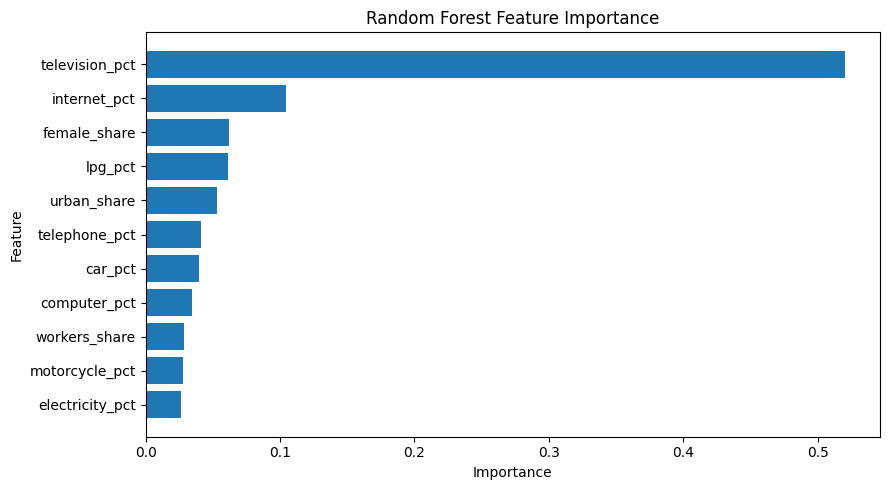

In [12]:
# Feature importance
importance = (
    pd.Series(model.feature_importances_, index=MODEL_FEATURES)
    .sort_values(ascending=True)
)

plt.figure(figsize=(9, 5))
plt.barh(importance.index, importance.values)
plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()


## 9. Final Analytical Notes

The model's R², MAE and RMSE are calculated from the actual dataset when this notebook is run.

Feature importance describes how the fitted Random Forest used the available input features. It does **not** prove that any individual feature causes literacy outcomes.

The dataset is historical and aggregate. The project should therefore be treated as an educational analytics demonstration.


# 10. Full Flask Backend + Frontend 

The following cell contains the **entire web application**.

There is no separate `app.py`, `index.html`, `styles.css`, or JavaScript file required.

The Flask backend serves the frontend directly with `render_template_string()`, while JavaScript calls Flask REST endpoints for:

- Overview KPIs
- State summaries
- District explorer
- Five insight cards
- Model metrics
- Feature importance
- Interactive literacy-rate estimation


In [ ]:
# ==========================================================
# SINGLE-FILE WEB APP
# Flask backend + HTML + CSS + JavaScript frontend
# ==========================================================

APP = Flask(__name__)

# -----------------------------
# Backend API helpers
# -----------------------------

def clean_json_records(frame):
    return frame.replace({np.nan: None}).to_dict(orient="records")


def get_state_summary():
    result = df.groupby("State name").agg({
        "Population": "sum",
        "Male": "sum",
        "Female": "sum",
        "Literate": "sum",
        "Workers": "sum",
        "Households": "sum",
        "Housholds_with_Electric_Lighting": "sum",
        "Households_with_Internet": "sum",
        "Households_with_Computer": "sum",
        "Urban_Households": "sum"
    }).reset_index()

    result["literacy_rate"] = result["Literate"] / result["Population"] * 100
    result["sex_ratio"] = result["Female"] / result["Male"].replace(0, np.nan) * 1000
    result["electricity_pct"] = (
        result["Housholds_with_Electric_Lighting"] /
        result["Households"].replace(0, np.nan) * 100
    )
    result["internet_pct"] = (
        result["Households_with_Internet"] /
        result["Households"].replace(0, np.nan) * 100
    )
    result["urban_share"] = (
        result["Urban_Households"] /
        result["Households"].replace(0, np.nan) * 100
    )
    return result


def get_summary():
    total_population = int(df["Population"].sum())
    total_literate = int(df["Literate"].sum())

    return {
        "districts": int(df["District name"].nunique()),
        "states": int(df["State name"].nunique()),
        "population": total_population,
        "literacy_rate": round(total_literate / total_population * 100, 2),
        "avg_district_literacy": round(float(df["literacy_rate"].mean()), 2),
        "avg_sex_ratio": round(float(df["sex_ratio"].mean()), 1),
        "avg_electricity": round(float(df["electricity_pct"].mean()), 2),
        "avg_internet": round(float(df["internet_pct"].mean()), 2)
    }


# -----------------------------
# API routes
# -----------------------------

@APP.get("/api/summary")
def api_summary():
    return jsonify(get_summary())


@APP.get("/api/states")
def api_states():
    state = get_state_summary()
    columns = [
        "State name", "Population", "literacy_rate", "sex_ratio",
        "electricity_pct", "internet_pct", "urban_share"
    ]
    return jsonify(
        clean_json_records(
            state.sort_values("Population", ascending=False)[columns]
        )
    )


@APP.get("/api/districts")
def api_districts():
    selected_state = request.args.get("state", "All States")
    limit = int(request.args.get("limit", 50))

    data = df.copy()

    if selected_state != "All States":
        data = data[data["State name"] == selected_state]

    columns = [
        "District name", "State name", "Population",
        "literacy_rate", "sex_ratio",
        "electricity_pct", "internet_pct", "urban_share"
    ]

    return jsonify(
        clean_json_records(
            data.sort_values("literacy_rate", ascending=False)[columns].head(limit)
        )
    )


@APP.get("/api/insights")
def api_insights():
    state = get_state_summary()

    top_population = state.nlargest(1, "Population").iloc[0]
    top_literacy = state.nlargest(1, "literacy_rate").iloc[0]
    low_literacy = state.nsmallest(1, "literacy_rate").iloc[0]

    return jsonify([
        {
            "title": "Population concentration",
            "text": f"{top_population['State name']} has the largest aggregate population in the state-level summary."
        },
        {
            "title": "Literacy varies",
            "text": (
                f"State-level literacy spans from approximately "
                f"{low_literacy['literacy_rate']:.1f}% to "
                f"{top_literacy['literacy_rate']:.1f}% across the aggregated data."
            )
        },
        {
            "title": "Infrastructure is comparable",
            "text": "Electricity, internet, computer, telephone and other household indicators can be compared with literacy patterns."
        },
        {
            "title": "District detail matters",
            "text": "State averages can hide internal variation, so the district explorer provides a more granular view."
        },
        {
            "title": "Prediction is an estimate",
            "text": "The machine-learning panel estimates literacy rate from selected aggregate indicators and is not a causal model."
        }
    ])


@APP.get("/api/model")
def api_model():
    importances = (
        pd.Series(model.feature_importances_, index=MODEL_FEATURES)
        .sort_values(ascending=False)
    )

    return jsonify({
        "r2": round(float(r2), 4),
        "mae": round(float(mae), 4),
        "rmse": round(float(rmse), 4),
        "features": [
            {
                "feature": feature,
                "importance": round(float(value), 4)
            }
            for feature, value in importances.items()
        ]
    })


@APP.post("/api/predict")
def api_predict():
    payload = request.get_json(force=True)

    missing = [feature for feature in MODEL_FEATURES if feature not in payload]
    if missing:
        return jsonify({
            "error": "Missing fields: " + ", ".join(missing)
        }), 400

    try:
        values = [float(payload[feature]) for feature in MODEL_FEATURES]
    except (TypeError, ValueError):
        return jsonify({
            "error": "All prediction inputs must be numeric percentages."
        }), 400

    row = pd.DataFrame([values], columns=MODEL_FEATURES)
    prediction = float(model.predict(row)[0])

    return jsonify({
        "predicted_literacy_rate": round(
            max(0.0, min(100.0, prediction)), 2
        ),
        "note": (
            "Model estimate based on aggregate 2011 Census-derived "
            "features. This is not an official literacy figure."
        )
    })


# -----------------------------
# Full frontend
# -----------------------------

INDEX_HTML = r"""
<!doctype html>
<html lang="en">
<head>
<meta charset="utf-8">
<meta name="viewport" content="width=device-width, initial-scale=1">

<title>India Census 2011 — Insight Lab</title>

<script src="https://cdn.jsdelivr.net/npm/chart.js"></script>

<style>
:root{
  --ink:#151923;
  --muted:#687284;
  --line:#e8ecf2;
  --bg:#f7f8fb;
  --panel:#ffffff;
  --blue:#2f6fed;
  --green:#14a47b;
  --shadow:0 12px 38px rgba(21,25,35,.06);
  --radius:20px;
}

*{box-sizing:border-box}

html{scroll-behavior:smooth}

body{
  margin:0;
  font-family:Inter,ui-sans-serif,system-ui,-apple-system,Segoe UI,sans-serif;
  color:var(--ink);
  background:var(--bg);
}

a{text-decoration:none;color:inherit}

.topbar{
  position:sticky;
  top:0;
  z-index:20;
  height:76px;
  padding:0 6vw;
  display:flex;
  align-items:center;
  justify-content:space-between;
  background:rgba(255,255,255,.92);
  backdrop-filter:blur(14px);
  border-bottom:1px solid var(--line);
}

.brand{
  display:flex;
  align-items:center;
  gap:12px;
}

.brand-mark{
  width:40px;
  height:40px;
  border-radius:12px;
  display:grid;
  place-items:center;
  background:var(--ink);
  color:#fff;
  font-weight:900;
}

.brand-title{font-weight:900}
.brand-subtitle{
  margin-top:2px;
  font-size:12px;
  color:var(--muted);
}

.source-pill{
  border:1px solid var(--line);
  background:#fff;
  padding:10px 14px;
  border-radius:999px;
  font-size:12px;
  font-weight:800;
}

main{
  max-width:1280px;
  margin:0 auto;
  padding:0 4vw;
}

.hero{
  display:grid;
  grid-template-columns:1.45fr .85fr;
  gap:44px;
  align-items:center;
  padding:88px 0 68px;
}

.eyebrow{
  font-size:11px;
  letter-spacing:.15em;
  text-transform:uppercase;
  color:var(--blue);
  font-weight:900;
}

.hero h1{
  font-size:clamp(44px,6vw,76px);
  line-height:.98;
  letter-spacing:-.065em;
  margin:18px 0 24px;
}

.hero h1 span{color:var(--blue)}

.hero-copy{
  max-width:720px;
  font-size:18px;
  line-height:1.65;
  color:#566071;
}

.hero-actions{
  display:flex;
  gap:12px;
  margin-top:28px;
}

.button{
  min-height:46px;
  padding:0 18px;
  border-radius:12px;
  border:1px solid transparent;
  display:inline-flex;
  align-items:center;
  justify-content:center;
  font-weight:900;
  cursor:pointer;
}

.button.primary{background:var(--ink);color:#fff}
.button.secondary{background:#fff;border-color:var(--line)}
.button.full{width:100%;margin-top:14px}

.hero-card{
  padding:28px;
  color:#fff;
  background:linear-gradient(140deg,#111721,#1f2a3b);
  border-radius:28px;
  box-shadow:0 22px 70px rgba(21,25,35,.17);
}

.hero-card small{
  color:rgba(255,255,255,.55);
  text-transform:uppercase;
  letter-spacing:.14em;
  font-weight:800;
}

.flow{
  display:flex;
  flex-wrap:wrap;
  gap:9px;
  align-items:center;
  margin:20px 0;
}

.flow span{
  padding:10px 11px;
  border:1px solid rgba(255,255,255,.1);
  background:rgba(255,255,255,.06);
  border-radius:11px;
  font-weight:800;
  font-size:12px;
}

.flow i{
  opacity:.45;
  font-style:normal;
}

.section{padding:48px 0}

.section-heading{
  display:flex;
  justify-content:space-between;
  align-items:flex-end;
  gap:20px;
  margin-bottom:22px;
}

h2{
  margin:10px 0 0;
  font-size:34px;
  line-height:1.05;
  letter-spacing:-.04em;
}

h3{
  margin:5px 0 0;
  font-size:20px;
  letter-spacing:-.02em;
}

.muted{
  color:var(--muted);
  font-size:13px;
}

.kpi-grid{
  display:grid;
  grid-template-columns:repeat(7,1fr);
  gap:12px;
}

.kpi{
  background:var(--panel);
  border:1px solid var(--line);
  border-radius:18px;
  padding:17px;
  box-shadow:var(--shadow);
}

.kpi-label{
  font-size:11px;
  color:var(--muted);
  font-weight:800;
}

.kpi-value{
  margin-top:8px;
  font-size:26px;
  font-weight:900;
  letter-spacing:-.045em;
}

.kpi-sub{
  margin-top:7px;
  color:#8b93a2;
  font-size:10px;
}

.chart-grid{
  display:grid;
  grid-template-columns:1fr 1fr;
  gap:16px;
  margin-top:16px;
}

.panel{
  background:var(--panel);
  border:1px solid var(--line);
  border-radius:var(--radius);
  box-shadow:var(--shadow);
  padding:22px;
}

.chart-panel canvas{
  height:285px!important;
}

.insight-grid{
  display:grid;
  grid-template-columns:repeat(5,1fr);
  gap:12px;
}

.insight-card{
  padding:18px;
  min-height:220px;
  background:#fff;
  border:1px solid var(--line);
  border-radius:18px;
}

.insight-index{
  color:var(--blue);
  font-size:11px;
  letter-spacing:.12em;
  font-weight:900;
}

.insight-card h3{margin-top:20px}

.insight-card p{
  color:var(--muted);
  line-height:1.6;
  font-size:13px;
}

.controls{
  display:flex;
  gap:9px;
}

.controls select,
.form-grid input{
  height:42px;
  border:1px solid var(--line);
  border-radius:11px;
  background:#fff;
  padding:0 12px;
  font:inherit;
  color:var(--ink);
}

.table-panel{overflow:auto}

table{
  width:100%;
  min-width:820px;
  border-collapse:collapse;
}

th,td{
  text-align:left;
  padding:12px 10px;
  border-bottom:1px solid var(--line);
  font-size:13px;
}

th{
  color:var(--muted);
  font-size:10px;
  text-transform:uppercase;
  letter-spacing:.08em;
}

.model-grid{
  display:grid;
  grid-template-columns:1fr 1fr;
  gap:16px;
}

.form-grid{
  display:grid;
  grid-template-columns:1fr 1fr;
  gap:12px;
}

.form-grid label{
  display:flex;
  flex-direction:column;
  gap:6px;
}

.form-grid label span{
  color:var(--muted);
  font-size:10px;
  font-weight:800;
}

.prediction-result{
  margin-top:14px;
  padding:16px;
  border-radius:14px;
  background:#eef8f5;
  border:1px solid #d7eee6;
}

.result-label{
  font-size:10px;
  text-transform:uppercase;
  letter-spacing:.1em;
  color:var(--green);
  font-weight:900;
}

.result-value{
  margin-top:6px;
  font-size:31px;
  font-weight:900;
  letter-spacing:-.045em;
}

.result-note{
  margin-top:8px;
  font-size:11px;
  line-height:1.5;
  color:var(--muted);
}

.hidden{display:none}

.metric-list{
  border-top:1px solid var(--line);
  margin-top:10px;
}

.metric-row{
  display:flex;
  justify-content:space-between;
  padding:13px 0;
  border-bottom:1px solid var(--line);
}

.metric-row span{font-size:13px;color:var(--muted)}
.metric-row strong{font-size:17px}

.mini-note{
  margin:14px 0 18px;
  font-size:12px;
  color:var(--muted);
  line-height:1.6;
}

.final-card{
  padding:30px;
  border-radius:28px;
  border:1px solid #dae3f0;
  background:linear-gradient(135deg,#eff4ff,#eefaf5);
}

.final-card h2{max-width:750px}

.final-card p{
  max-width:900px;
  color:#566071;
  line-height:1.7;
}

footer{
  display:flex;
  justify-content:space-between;
  gap:20px;
  padding:28px 6vw;
  border-top:1px solid var(--line);
  color:var(--muted);
  font-size:11px;
}

@media(max-width:1100px){
  .hero{grid-template-columns:1fr}
  .kpi-grid{grid-template-columns:repeat(4,1fr)}
  .insight-grid{grid-template-columns:repeat(2,1fr)}
  .chart-grid,.model-grid{grid-template-columns:1fr}
}

@media(max-width:650px){
  .topbar{padding:0 4vw}
  main{padding:0 4vw}
  .hero{padding-top:55px}
  .hero h1{font-size:48px}
  .kpi-grid{grid-template-columns:1fr 1fr}
  .insight-grid{grid-template-columns:1fr}
  .form-grid{grid-template-columns:1fr}
  .section-heading{
    flex-direction:column;
    align-items:flex-start;
  }
  .controls{width:100%}
  .controls select{flex:1}
  footer{flex-direction:column}
}
</style>
</head>

<body>

<header class="topbar">
  <div class="brand">
    <div class="brand-mark">IC</div>
    <div>
      <div class="brand-title">Insight Lab</div>
      <div class="brand-subtitle">India Census 2011 Analytics</div>
    </div>
  </div>

  <a class="source-pill"
     href="https://www.kaggle.com/danofer/india-census"
     target="_blank">
    Kaggle source ↗
  </a>
</header>

<main>

<section class="hero">

  <div>
    <div class="eyebrow">
      AICTE • IBM SkillsBuild • Data Analytics with AI
    </div>

    <h1>
      Understand districts.<br>
      <span>Find patterns.</span>
    </h1>

    <p class="hero-copy">
      An interactive analytics workspace built on India Census 2011
      district-level data. Explore population, literacy, demographic
      structure and household infrastructure, then test a machine-learning
      estimate of district literacy rate.
    </p>

    <div class="hero-actions">
      <a class="button primary" href="#dashboard">
        Explore dashboard
      </a>

      <a class="button secondary"
         href="https://www.kaggle.com/danofer/india-census?select=india-districts-census-2011.csv"
         target="_blank">
        Open dataset
      </a>
    </div>
  </div>

  <div class="hero-card">
    <small>Project flow</small>

    <div class="flow">
      <span>Data</span><i>→</i>
      <span>EDA</span><i>→</i>
      <span>Insights</span><i>→</i>
      <span>Model</span><i>→</i>
      <span>Action</span>
    </div>

    <div style="font-size:12px;opacity:.65;line-height:1.6">
      Single Jupyter Notebook • Flask API • HTML/CSS/JS frontend
    </div>
  </div>

</section>

<section id="dashboard" class="section">

  <div class="section-heading">
    <div>
      <div class="eyebrow">01 / overview</div>
      <h2>The big picture</h2>
    </div>

    <div class="muted">
      Calculated from the Census dataset at runtime
    </div>
  </div>

  <div id="kpis" class="kpi-grid"></div>

  <div class="chart-grid">

    <div class="panel chart-panel">
      <div class="panel-head">
        <div>
          <div class="muted">Population</div>
          <h3>Largest state aggregates</h3>
        </div>
      </div>
      <canvas id="populationChart"></canvas>
    </div>

    <div class="panel chart-panel">
      <div class="panel-head">
        <div>
          <div class="muted">Literacy</div>
          <h3>Highest literacy rates</h3>
        </div>
      </div>
      <canvas id="literacyChart"></canvas>
    </div>

  </div>

  <div class="chart-grid">

    <div class="panel chart-panel">
      <div class="panel-head">
        <div>
          <div class="muted">Infrastructure</div>
          <h3>Electricity coverage</h3>
        </div>
      </div>
      <canvas id="electricityChart"></canvas>
    </div>

    <div class="panel chart-panel">
      <div class="panel-head">
        <div>
          <div class="muted">Digital access</div>
          <h3>Internet coverage</h3>
        </div>
      </div>
      <canvas id="internetChart"></canvas>
    </div>

  </div>

</section>

<section class="section">

  <div class="section-heading">
    <div>
      <div class="eyebrow">02 / story</div>
      <h2>Five things worth noticing</h2>
    </div>
  </div>

  <div id="insights" class="insight-grid"></div>

</section>

<section class="section">

  <div class="section-heading">

    <div>
      <div class="eyebrow">03 / district explorer</div>
      <h2>Drill down</h2>
    </div>

    <div class="controls">
      <select id="stateFilter">
        <option>All States</option>
      </select>

      <select id="limitFilter">
        <option>20</option>
        <option selected>50</option>
        <option>100</option>
      </select>
    </div>

  </div>

  <div class="panel table-panel">

    <table>

      <thead>
        <tr>
          <th>District</th>
          <th>State</th>
          <th>Population</th>
          <th>Literacy</th>
          <th>Sex ratio</th>
          <th>Electricity</th>
          <th>Internet</th>
        </tr>
      </thead>

      <tbody id="districtTable"></tbody>

    </table>

  </div>

</section>

<section class="section">

  <div class="section-heading">

    <div>
      <div class="eyebrow">04 / AI prediction</div>
      <h2>Estimate district literacy</h2>
    </div>

    <div class="muted">
      Random Forest regression
    </div>

  </div>

  <div class="model-grid">

    <div class="panel">

      <div class="panel-head">
        <div>
          <div class="muted">Prediction inputs</div>
          <h3>Describe the district</h3>
        </div>
      </div>

      <div id="modelForm" class="form-grid"></div>

      <button id="predictButton"
              class="button primary full">
        Estimate literacy rate
      </button>

      <div id="predictionResult"
           class="prediction-result hidden">
      </div>

    </div>

    <div class="panel">

      <div class="panel-head">
        <div>
          <div class="muted">Model quality</div>
          <h3>How it performs</h3>
        </div>
      </div>

      <div id="modelMetrics" class="metric-list"></div>

      <div class="mini-note">
        R², MAE and RMSE are measured on a held-out test split.
        Feature importance describes model behavior and does not prove
        causation.
      </div>

      <canvas id="importanceChart"></canvas>

    </div>

  </div>

</section>

<section class="section">

  <div class="final-card">

    <div class="eyebrow">05 / responsible use</div>

    <h2>
      Use the model as a lens, not a verdict.
    </h2>

    <p>
      Census 2011 is historical aggregate data. The dashboard highlights
      patterns and associations; it does not establish causation, represent
      current conditions, or justify individual-level decisions.
    </p>

  </div>

</section>

</main>

<footer>
  <span>India Census 2011 Insight Lab</span>
  <span>Kaggle dataset • Python + Flask + HTML/CSS/JS</span>
</footer>

<script>
let charts = {};

const fmtNumber = n =>
  Number(n).toLocaleString("en-IN");

const fmtPct = n =>
  `${Number(n).toFixed(1)}%`;

function renderKpis(summary){

  const items = [
    ["Districts", fmtNumber(summary.districts), "unique district rows"],
    ["States / UTs", fmtNumber(summary.states), "state labels"],
    ["Population", fmtNumber(summary.population), "aggregate"],
    ["Literacy", `${summary.literacy_rate}%`, "population-weighted"],
    ["Avg. district literacy", `${summary.avg_district_literacy}%`, "simple average"],
    ["Avg. sex ratio", summary.avg_sex_ratio, "per 1,000 males"],
    ["Internet", `${summary.avg_internet}%`, "avg. household coverage"]
  ];

  document.getElementById("kpis").innerHTML =
    items.map(x =>
      `<div class="kpi">
        <div class="kpi-label">${x[0]}</div>
        <div class="kpi-value">${x[1]}</div>
        <div class="kpi-sub">${x[2]}</div>
      </div>`
    ).join("");

}

function createBarChart(id, labels, values, label){

  if(charts[id])
    charts[id].destroy();

  charts[id] = new Chart(
    document.getElementById(id),
    {
      type:"bar",

      data:{
        labels:labels,
        datasets:[
          {
            label:label,
            data:values,
            borderRadius:8,
            backgroundColor:"#2f6fed"
          }
        ]
      },

      options:{
        responsive:true,
        maintainAspectRatio:false,

        plugins:{
          legend:{display:false}
        },

        scales:{
          x:{
            grid:{display:false},
            ticks:{color:"#687284"}
          },

          y:{
            grid:{color:"#edf0f4"},
            ticks:{color:"#687284"}
          }
        }
      }
    }
  );

}

async function loadDashboard(){

  const [summary, states, insights, model] =
    await Promise.all([
      fetch("/api/summary").then(r=>r.json()),
      fetch("/api/states").then(r=>r.json()),
      fetch("/api/insights").then(r=>r.json()),
      fetch("/api/model").then(r=>r.json())
    ]);

  renderKpis(summary);

  document.getElementById("insights").innerHTML =
    insights.map((x,i) =>
      `<article class="insight-card">
        <div class="insight-index">0${i+1}</div>
        <h3>${x.title}</h3>
        <p>${x.text}</p>
      </article>`
    ).join("");

  let pop =
    states.slice(0,8);

  createBarChart(
    "populationChart",
    pop.map(x=>x["State name"]),
    pop.map(x=>x.Population),
    "Population"
  );

  let lit =
    [...states]
      .sort((a,b)=>b.literacy_rate-a.literacy_rate)
      .slice(0,8);

  createBarChart(
    "literacyChart",
    lit.map(x=>x["State name"]),
    lit.map(x=>x.literacy_rate),
    "Literacy %"
  );

  let electricity =
    [...states]
      .sort((a,b)=>b.electricity_pct-a.electricity_pct)
      .slice(0,8);

  createBarChart(
    "electricityChart",
    electricity.map(x=>x["State name"]),
    electricity.map(x=>x.electricity_pct),
    "Electricity %"
  );

  let internet =
    [...states]
      .sort((a,b)=>b.internet_pct-a.internet_pct)
      .slice(0,8);

  createBarChart(
    "internetChart",
    internet.map(x=>x["State name"]),
    internet.map(x=>x.internet_pct),
    "Internet %"
  );

  let stateSelect =
    document.getElementById("stateFilter");

  stateSelect.innerHTML =
    `<option>All States</option>` +
    states.map(x =>
      `<option>${x["State name"]}</option>`
    ).join("");

  renderModel(model);
  renderForm();
  loadDistricts();
}

async function loadDistricts(){

  let state =
    document.getElementById("stateFilter").value;

  let limit =
    document.getElementById("limitFilter").value;

  let rows =
    await fetch(
      `/api/districts?state=${encodeURIComponent(state)}&limit=${limit}`
    ).then(r=>r.json());

  document.getElementById("districtTable").innerHTML =
    rows.map(x =>
      `<tr>
        <td>${x["District name"]}</td>
        <td>${x["State name"]}</td>
        <td>${fmtNumber(x.Population)}</td>
        <td>${fmtPct(x.literacy_rate)}</td>
        <td>${Number(x.sex_ratio).toFixed(0)}</td>
        <td>${fmtPct(x.electricity_pct)}</td>
        <td>${fmtPct(x.internet_pct)}</td>
      </tr>`
    ).join("");

}

function renderModel(model){

  document.getElementById("modelMetrics").innerHTML =
    [
      ["R²", model.r2.toFixed(3)],
      ["MAE", `${model.mae.toFixed(2)} pp`],
      ["RMSE", `${model.rmse.toFixed(2)} pp`]
    ].map(x =>
      `<div class="metric-row">
        <span>${x[0]}</span>
        <strong>${x[1]}</strong>
      </div>`
    ).join("");

  const top =
    model.features.slice(0,8);

  if(charts.importance)
    charts.importance.destroy();

  charts.importance =
    new Chart(
      document.getElementById("importanceChart"),
      {
        type:"bar",

        data:{
          labels:
            top.map(x=>x.feature.replaceAll("_"," ")),

          datasets:[
            {
              data:
                top.map(x=>x.importance),

              backgroundColor:"#14a47b",
              borderRadius:8
            }
          ]
        },

        options:{
          indexAxis:"y",
          responsive:true,
          plugins:{
            legend:{display:false}
          }
        }
      }
    );

}

const fields = [
  ["female_share","Female population share (%)"],
  ["workers_share","Workers share (%)"],
  ["urban_share","Urban households (%)"],
  ["electricity_pct","Electricity households (%)"],
  ["internet_pct","Internet households (%)"],
  ["computer_pct","Computer households (%)"],
  ["lpg_pct","LPG / PNG households (%)"],
  ["television_pct","Television households (%)"],
  ["telephone_pct","Telephone / mobile households (%)"],
  ["car_pct","Car / jeep / van households (%)"],
  ["motorcycle_pct","Scooter / motorcycle households (%)"]
];

function renderForm(){

  document.getElementById("modelForm").innerHTML =
    fields.map(x =>
      `<label>
        <span>${x[1]}</span>
        <input
          id="${x[0]}"
          type="number"
          min="0"
          max="100"
          step="0.1"
          value="50"
        >
      </label>`
    ).join("");

}

document
  .getElementById("predictButton")
  .addEventListener("click", async ()=>{

    let payload = {};

    fields.forEach(x=>{
      payload[x[0]] =
        Number(
          document.getElementById(x[0]).value || 0
        );
    });

    let response =
      await fetch(
        "/api/predict",
        {
          method:"POST",
          headers:{
            "Content-Type":"application/json"
          },
          body:JSON.stringify(payload)
        }
      ).then(r=>r.json());

    let box =
      document.getElementById("predictionResult");

    box.classList.remove("hidden");

    if(response.error){

      box.innerHTML =
        `<div class="result-label">
          Input error
        </div>

        <div class="result-value">
          ${response.error}
        </div>`;

    }else{

      box.innerHTML =
        `<div class="result-label">
          Estimated district literacy
        </div>

        <div class="result-value">
          ${response.predicted_literacy_rate}%
        </div>

        <div class="result-note">
          ${response.note}
        </div>`;

    }

  });

document
  .getElementById("stateFilter")
  .addEventListener("change", loadDistricts);

document
  .getElementById("limitFilter")
  .addEventListener("change", loadDistricts);

loadDashboard();

</script>
</body>
</html>
"""


@APP.get("/")
def home():
    return render_template_string(INDEX_HTML)


# -----------------------------
# Run the web app
# -----------------------------
def run_app():
    APP.run(
        host="127.0.0.1",
        port=5000,
        debug=False,
        use_reloader=False
    )


# Start Flask in a background thread.
server_thread = threading.Thread(
    target=run_app,
    daemon=True
)
server_thread.start()

time.sleep(2)

print("Flask backend started.")
print("Open http://127.0.0.1:5000 in your browser.")

# Local Jupyter/IPython helper.
try:
    from IPython.display import IFrame, display
    display(IFrame(
        src="http://127.0.0.1:5000",
        width="100%",
        height=900
    ))
except Exception:
    pass

# Google Colab helper, if available.
try:
    from google.colab.output import serve_kernel_port_as_window
    serve_kernel_port_as_window(5000)
except Exception:
    pass


 * Serving Flask app '__main__'
 * Debug mode: off


 * Running on http://127.0.0.1:5000
Press CTRL+C to quit


Flask backend started.
Open http://127.0.0.1:5000 in your browser.


127.0.0.1 - - [25/Sep/2026 02:35:36] "GET / HTTP/1.1" 200 -
127.0.0.1 - - [25/Sep/2026 02:35:37] "GET /api/summary HTTP/1.1" 200 -
127.0.0.1 - - [25/Sep/2026 02:35:37] "GET /api/insights HTTP/1.1" 200 -
127.0.0.1 - - [25/Sep/2026 02:35:37] "GET /api/states HTTP/1.1" 200 -
127.0.0.1 - - [25/Sep/2026 02:35:37] "GET /api/model HTTP/1.1" 200 -
127.0.0.1 - - [25/Sep/2026 02:35:37] "GET /api/districts?state=All%20States&limit=50 HTTP/1.1" 200 -
